# Audit d'équité du modèle de retard par région

**Question** : le modèle de retard est-il aussi performant pour les clients de toutes les régions du Brésil ?

L'EDA a montré que les retards sont beaucoup plus fréquents au Nord et au Nord-Est. Si le modèle détectait moins bien les retards dans ces régions, les clients déjà les plus pénalisés seraient aussi les moins bien prévenus.

On compare, pour chacune des **5 grandes régions** du Brésil (découpage officiel de l'IBGE) :
- le **taux de retard réel** et le **taux d'alertes** du modèle ;
- le **rappel** : part des vrais retards détectés (égalité des chances de détection) ;
- la **précision** : part des alertes qui sont de vrais retards ;
- le **taux de fausses alertes** : part des commandes à l'heure signalées à tort.

Le modèle est réentraîné exactement comme dans `03_modele_retard.ipynb` (même découpage, mêmes paramètres), puis évalué sur le jeu de test.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import train_test_split
from sqlalchemy import create_engine

# On se place à la racine du projet pour que le fichier .env soit trouvé
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

from shoppulse.config import settings
from shoppulse.models.delay import charger_donnees, creer_pipeline

engine = create_engine(settings.database_url)

## 1. Modèle et prédictions sur le jeu de test

In [2]:
X, y = charger_donnees(engine)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

modele = creer_pipeline(
    RandomForestClassifier(
        n_estimators=100, max_depth=12, class_weight="balanced", n_jobs=-1, random_state=42
    )
)
modele.fit(X_train, y_train)

test = X_test.copy()
test["reel"] = y_test
test["predit"] = modele.predict(X_test)
print(len(test), "commandes dans le jeu de test")

19294 commandes dans le jeu de test


## 2. Métriques par région

In [3]:
regions = {
    "Norte": ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "Nordeste": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Centro-Oeste": ["DF", "GO", "MT", "MS"],
    "Sudeste": ["ES", "MG", "RJ", "SP"],
    "Sul": ["PR", "RS", "SC"],
}


def trouver_region(etat):
    for region, etats in regions.items():
        if etat in etats:
            return region
    return "Inconnue"


test["region"] = test["customer_state"].apply(trouver_region)

lignes = []
for region in regions:
    groupe = test[test["region"] == region]
    a_l_heure = groupe[groupe["reel"] == 0]
    lignes.append({
        "region": region,
        "nb_commandes": len(groupe),
        "taux_retard_reel_%": round(100 * groupe["reel"].mean(), 1),
        "taux_alertes_%": round(100 * groupe["predit"].mean(), 1),
        "rappel": round(recall_score(groupe["reel"], groupe["predit"]), 3),
        "precision": round(precision_score(groupe["reel"], groupe["predit"], zero_division=0), 3),
        "taux_fausses_alertes": round(a_l_heure["predit"].mean(), 3),
    })

audit = pd.DataFrame(lignes).set_index("region")
audit

,nb_commandes,taux_retard_reel_%,taux_alertes_%,rappel,precision,taux_fausses_alertes
region,,,,,,
Norte,366,10.9,22.4,0.500,0.244,0.190
Nordeste,1822,14.2,48.2,0.783,0.230,0.432
Centro-Oeste,1117,7.7,25.8,0.581,0.174,0.231
Sudeste,13194,7.4,15.3,0.504,0.244,0.124
Sul,2795,7.3,16.7,0.493,0.216,0.142


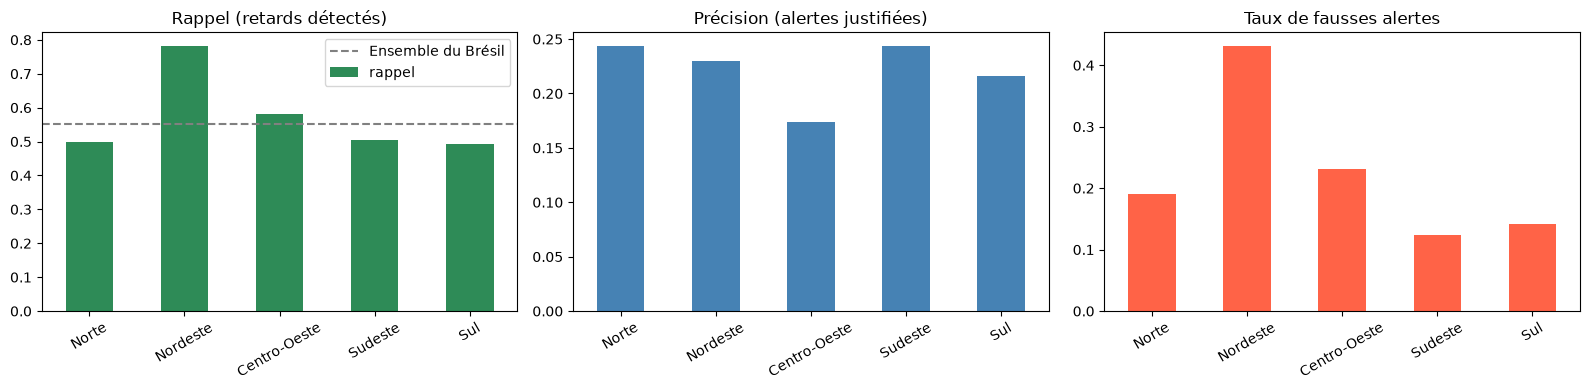

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

audit["rappel"].plot.bar(ax=axes[0], color="seagreen")
axes[0].axhline(recall_score(test["reel"], test["predit"]), linestyle="--", color="grey",
                label="Ensemble du Brésil")
axes[0].set_title("Rappel (retards détectés)")
axes[0].legend()

audit["precision"].plot.bar(ax=axes[1], color="steelblue")
axes[1].set_title("Précision (alertes justifiées)")

audit["taux_fausses_alertes"].plot.bar(ax=axes[2], color="tomato")
axes[2].set_title("Taux de fausses alertes")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 3. Conclusions

**1. Détection des retards (rappel) : pas de désavantage pour les régions les plus touchées.**
Le Nordeste, où les retards sont les plus fréquents (14,2 %), a le **meilleur rappel** : 78 % de ses retards sont détectés, contre 50 % environ dans le Sudeste et le Sul. Les clients les plus exposés aux retards sont donc les mieux protégés.

**2. Fiabilité des alertes (précision) : homogène.**
Entre 17 % et 24 % des alertes correspondent à un vrai retard, quelle que soit la région. Une alerte a donc à peu près la même valeur partout.

**3. Fausses alertes : fortement déséquilibrées.**
Dans le Nordeste, **43 % des commandes à l'heure** sont signalées à tort, contre 12 % dans le Sudeste. Au total, presque **une commande sur deux** du Nordeste déclenche une alerte (48 %), contre 15 % dans le Sudeste. Le modèle s'appuie fortement sur la géographie (état du client, distance) : il « soupçonne » plus souvent les commandes du Nordeste.

**Est-ce un problème ?** Tout dépend de l'usage de l'alerte :
- si elle déclenche une **action favorable** au client (prévenir d'un retard possible, prioriser l'expédition, choisir un meilleur transporteur), le déséquilibre a un coût pour la logistique mais **profite** aux clients du Nordeste ;
- si elle servait à **pénaliser** le client (frais de port plus élevés, refus de vente, délai rallongé), ce serait une **discrimination géographique** à proscrire.

**Recommandations** :
- réserver l'usage du modèle à des **actions favorables** au client (règle inscrite dans la note éthique) ;
- **suivre ces métriques par région** à chaque réentraînement du modèle ;
- si le coût des fausses alertes devient trop élevé, **ajuster le seuil de décision par région** pour rapprocher les taux de fausses alertes ;
- tester une version du modèle **sans l'état du client** (en gardant la distance) et comparer l'équité obtenue.

**Limite** : le Norte ne compte que 366 commandes dans le jeu de test (environ 40 retards) : ses métriques sont moins fiables que celles des autres régions.